# EcoDrive — 03 · De la prédiction à la décision : alertes, styles de conduite, ROI
Le modèle de consommation sert la décision du lundi :
1. **Contrôler un véhicule** quand sa conso réelle dépasse nettement la conso prévue.
2. **Comparer les styles de conduite** et chiffrer ce qu'un conducteur économiserait en conduisant calmement.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_predict
from config import DATA, FIG, ROOT, TARGET, NUM_FEATURES, CAT_FEATURES, STYLE_MODIFIABLE, HYP
from modeles import MoyenneParVehicule, contexte, blocs, injecter_defauts, ecart_par_bloc, compter, sauver

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
df = pd.read_csv(DATA).sort_values("jour").reset_index(drop=True)
modele = joblib.load(ROOT / "reports" / "modele_conso.joblib")
coupure = int(len(df) * 0.8)
train, test = df.iloc[:coupure].copy(), df.iloc[coupure:].copy()
F = NUM_FEATURES + CAT_FEATURES
test["pred"] = modele.predict(test[F])
pd.Series(HYP, name="hypothèse").to_frame()

,hypothèse
flotte_vehicules,100.00
km_par_an,20000.00
prix_carburant,1.80
trajets_par_vehicule_an,440.00
taille_bloc,10.00
anomalies_par_an,12.00
cout_fausse_alerte,15.00
cout_vraie_alerte,90.00
cout_anomalie_ratee,400.00
abonnement_mois,4.00


## 1. Détection des consommations anormales
- **Unité :** chaque lundi, un véhicule thermique sur ses 10 derniers trajets. (Hybrides exclus : leur conso dépend
  de la batterie, non modélisée.)
- **Chaque véhicule comparé à lui-même :** son écart habituel au modèle (mesuré sur le train avec des prédictions
  hors échantillon) est retiré → on détecte un **changement**.
- **Évaluation sans étiquettes :** VED n'indique pas les défauts. On **injecte** des défauts connus (+15 à +40 %)
  sur 10 % des blocs, 30 fois avec des tirages différents.

In [2]:
oof = cross_val_predict(clone(modele), train[F], train[TARGET], cv=KFold(5, shuffle=True, random_state=42))
r = train.assign(ratio=train[TARGET] / oof).groupby("veh_id").ratio.agg(["median", "size"])
biais = (r["median"].where(r["size"] >= 5, 1.0) - 1)


def preparer_blocs(d):
    d = d[d.type_vehicule == "ICE"].copy()
    d["bloc"] = blocs(d.veh_id.to_numpy(), HYP["taille_bloc"])
    return d[d.bloc.isin(d.bloc.value_counts()[lambda s: s >= 5].index)].copy()


test = preparer_blocs(test)
test["pred_corr"] = test.pred * (1 + test.veh_id.map(biais).fillna(0))
test["pred_regle"] = MoyenneParVehicule().fit(train[F], train[TARGET]).predict(test[F])
print(f"{test.bloc.nunique()} blocs (5 à 10 trajets) dans le test")

43 blocs (5 à 10 trajets) dans le test


Coût calculé sur **une année de la flotte cliente** : 100 véhicules × 440 trajets / 10 = 4 400 contrôles par an,
12 défauts par an. **Coût annuel = FP × 15 € + TP × 90 € + FN × 400 €.**

**Le seuil est choisi sur le train** (prédictions hors échantillon `cross_val_predict`), puis vérifié **une seule
fois** sur le test. Choisir le seuil sur le test reviendrait à s'entraîner sur le test.

In [3]:
seuils = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
ctrl_an = HYP["flotte_vehicules"] * HYP["trajets_par_vehicule_an"] / HYP["taille_bloc"]


def simuler(d, col, n_sim=30):
    b, dist = d.bloc.to_numpy(), d.distance_km.to_numpy()
    tabs = []
    for k in range(n_sim):
        y_obs, lab = injecter_defauts(d[TARGET], b, seed=k)
        tabs.append(compter(ecart_par_bloc(y_obs, d[col], b, dist), lab, seuils))
    t = pd.concat(tabs).groupby("seuil").mean().reset_index()
    t["precision"] = t.TP / (t.TP + t.FP).replace(0, np.nan)
    t["recall"] = t.TP / (t.TP + t.FN)
    t["FP/an"] = (t.FP / t.n_normaux * ctrl_an).round(0)
    t["TP/an"] = (t.recall * HYP["anomalies_par_an"]).round(1)
    t["coût annuel (€)"] = (t["FP/an"] * HYP["cout_fausse_alerte"] + t["TP/an"] * HYP["cout_vraie_alerte"]
                            + (HYP["anomalies_par_an"] - t["TP/an"]) * HYP["cout_anomalie_ratee"]).round(0)
    return t.fillna(0)


# a) choix du seuil sur le train
tr = train.assign(pred=oof)
tr["pred_corr"] = tr.pred * (1 + tr.veh_id.map(biais).fillna(0))
tr = preparer_blocs(tr)
tab_train = simuler(tr, "pred_corr")
seuil_choisi = float(tab_train.loc[tab_train["coût annuel (€)"].idxmin(), "seuil"])
print(f"{tr.bloc.nunique()} blocs dans le train -> seuil choisi : +{seuil_choisi:.0%}")

# b) vérification unique sur le test
tab_m, tab_r = simuler(test, "pred_corr"), simuler(test, "pred_regle")
cout_sans = HYP["anomalies_par_an"] * HYP["cout_anomalie_ratee"]
print(f"Sans système : {cout_sans} €/an (défauts vus à la révision)")
tab_m[["seuil", "precision", "recall", "FP/an", "TP/an", "coût annuel (€)"]].round(3)

146 blocs dans le train -> seuil choisi : +15%
Sans système : 4800 €/an (défauts vus à la révision)


,seuil,precision,recall,FP/an,TP/an,coût annuel (€)
0,0.05,0.229,1.000,1636.0,12.0,25620.0
1,0.10,0.434,0.977,617.0,11.7,10428.0
2,0.15,0.606,0.961,303.0,11.5,5780.0
3,0.20,0.689,0.898,197.0,10.8,4407.0
4,0.25,1.000,0.781,0.0,9.4,1886.0
5,0.30,1.000,0.656,0.0,7.9,2351.0
6,0.40,1.000,0.227,0.0,2.7,3963.0


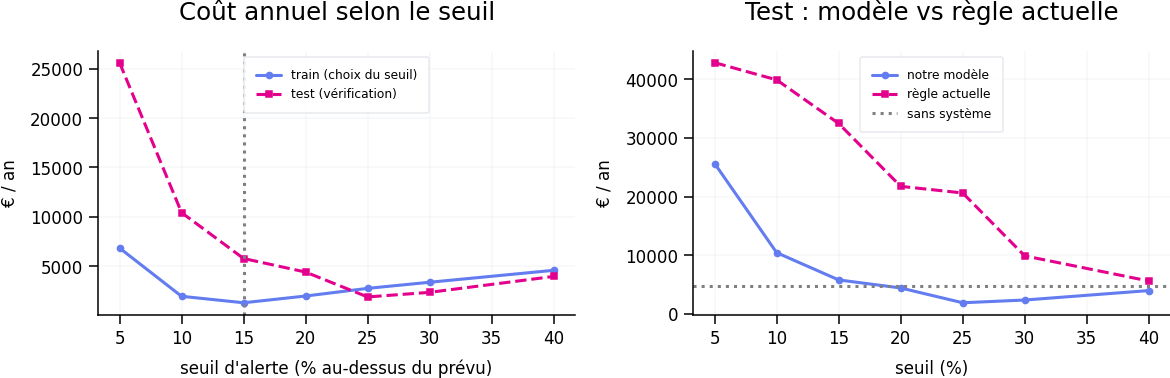

Test au seuil +15% : recall 96%, 303 fausses alertes/an, 5780 €/an (règle actuelle au même seuil : 32455 €/an)


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tab_train.seuil * 100, tab_train["coût annuel (€)"], "o-", label="train (choix du seuil)")
ax[0].plot(tab_m.seuil * 100, tab_m["coût annuel (€)"], "s--", label="test (vérification)")
ax[0].axvline(seuil_choisi * 100, color="grey", ls=":")
ax[0].set(title="Coût annuel selon le seuil", xlabel="seuil d'alerte (% au-dessus du prévu)", ylabel="€ / an"); ax[0].legend(fontsize=8)
ax[1].plot(tab_m.seuil * 100, tab_m["coût annuel (€)"], "o-", label="notre modèle")
ax[1].plot(tab_r.seuil * 100, tab_r["coût annuel (€)"], "s--", label="règle actuelle")
ax[1].axhline(cout_sans, color="grey", ls=":", label="sans système")
ax[1].set(title="Test : modèle vs règle actuelle", xlabel="seuil (%)", ylabel="€ / an"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "03_seuil_cout.png", bbox_inches="tight"); plt.show()
best = tab_m.loc[np.isclose(tab_m.seuil, seuil_choisi)].iloc[0]
best_r = tab_r.loc[np.isclose(tab_r.seuil, seuil_choisi)].iloc[0]
print(f"Test au seuil +{seuil_choisi:.0%} : recall {best.recall:.0%}, {best['FP/an']:.0f} fausses alertes/an, "
      f"{best['coût annuel (€)']:.0f} €/an (règle actuelle au même seuil : {best_r['coût annuel (€)']:.0f} €/an)")

**Lecture :** seuil bas = tous les défauts trouvés mais trop de fausses alertes ; seuil haut = défauts ratés.
Le seuil le moins coûteux sur le train est confirmé sur le test. La règle actuelle confond un trajet difficile
avec un défaut.

## 2. Comparer les styles de conduite
Pour chaque type de trajet (ville, mixte, autoroute), on classe les trajets en trois styles selon la part du temps
passé en accélération forte : **calme** (tiers le plus bas), **normal**, **nerveux** (tiers le plus haut).
On compare la conso réelle des thermiques à contexte égal.

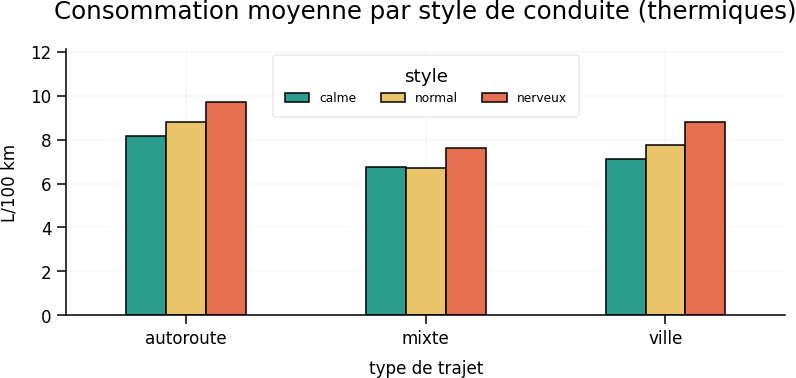

style,calme,normal,nerveux,écart nerveux / calme
contexte,,,,
autoroute,8.18,8.795,9.700,0.186
mixte,6.74,6.692,7.613,0.129
ville,7.14,7.770,8.815,0.235


In [5]:
st = df[df.type_vehicule == "ICE"].copy()
st["contexte"] = contexte(st)
st["style"] = st.groupby("contexte").part_accel_forte.transform(
    lambda s: pd.qcut(s.rank(method="first"), 3, labels=["calme", "normal", "nerveux"]))
comp_style = st.groupby(["contexte", "style"], observed=True)[TARGET].mean().unstack()[["calme", "normal", "nerveux"]]
comp_style["écart nerveux / calme"] = comp_style.nerveux / comp_style.calme - 1
fig, ax = plt.subplots(figsize=(7.5, 3.8))
comp_style[["calme", "normal", "nerveux"]].plot.bar(ax=ax, color=["#2a9d8f", "#e9c46a", "#e76f51"], rot=0)
ax.set(title="Consommation moyenne par style de conduite (thermiques)", xlabel="type de trajet", ylabel="L/100 km",
       ylim=(0, comp_style[["calme", "normal", "nerveux"]].values.max() * 1.25))
ax.legend(title="style", ncol=3, loc="upper center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "03_styles.png", bbox_inches="tight"); plt.show()
comp_style.round(3)

**Lecture :** à type de trajet égal, le style nerveux consomme plus que le style calme. Une partie de l'écart peut
venir du véhicule ; la section suivante compare donc **à véhicule et trajet identiques** grâce au modèle.

## 3. Potentiel d'éco-conduite (scénario « et s'il conduisait calmement ? »)
On garde le contexte du trajet et on remplace seulement les variables de style modifiables par la médiane des
trajets **calmes** du même type. Différence de conso prédite = potentiel d'économie.

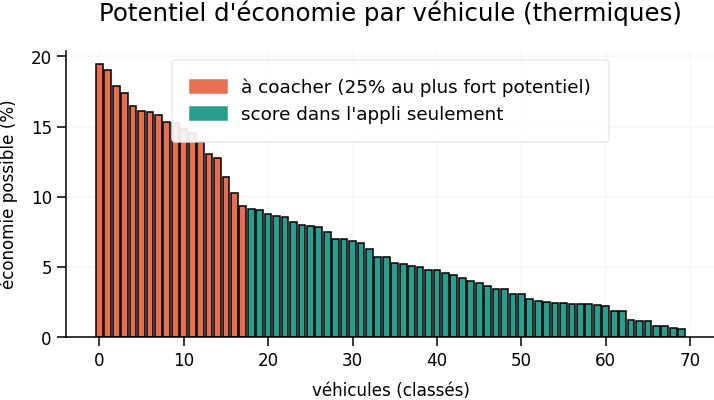

potentiel moyen : à coacher 14.9% | autres 4.5%


In [6]:
train["contexte"] = contexte(train)
calmes = train[train.part_accel_forte <= train.groupby("contexte").part_accel_forte.transform("median")]
ref = calmes.groupby("contexte")[STYLE_MODIFIABLE].median()
ice = df[df.type_vehicule == "ICE"].copy()
ice["contexte"] = contexte(ice)
X_eco = ice[F].copy()
for c in STYLE_MODIFIABLE:
    X_eco[c] = ice.contexte.map(ref[c]).to_numpy()
ice["potentiel"] = (1 - modele.predict(X_eco) / modele.predict(ice[F])).clip(min=0)
veh = ice.groupby("veh_id").potentiel.mean().sort_values(ascending=False).to_frame()
n_coach_veh = int(round(len(veh) * HYP["part_a_coacher"]))
veh["a_coacher"] = False
veh.iloc[:n_coach_veh, veh.columns.get_loc("a_coacher")] = True

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(veh)), veh.potentiel * 100, color=np.where(veh.a_coacher, "#e76f51", "#2a9d8f"))
ax.set(title="Potentiel d'économie par véhicule (thermiques)", xlabel="véhicules (classés)", ylabel="économie possible (%)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#e76f51"), plt.Rectangle((0, 0), 1, 1, color="#2a9d8f")],
          labels=[f"à coacher ({HYP['part_a_coacher']:.0%} au plus fort potentiel)", "score dans l'appli seulement"])
plt.tight_layout(); plt.savefig(FIG / "03_potentiel.png", bbox_inches="tight"); plt.show()
pot_coach, pot_autres = veh[veh.a_coacher].potentiel.mean(), veh[~veh.a_coacher].potentiel.mean()
print(f"potentiel moyen : à coacher {pot_coach:.1%} | autres {pot_autres:.1%}")

**Lecture :** le potentiel est concentré sur une minorité de conducteurs : on réserve le coaching (coûteux) à eux.

## 4. ROI (flotte de 100 véhicules)
Gain = carburant économisé + défauts évités. Coût an 1 = intégration + abonnement + coaching.
Sur 3 ans : pas de nouvelle intégration, 20 % de conducteurs à re-former chaque année.

In [7]:
conso_ice = ice[TARGET].mean()


def roi(cap_c, cap_a, prix=HYP["prix_carburant"], km=HYP["km_par_an"], abo=HYP["abonnement_mois"], rec=best.recall, fp=best["FP/an"]):
    n = HYP["flotte_vehicules"]; nc = round(n * HYP["part_a_coacher"]); l_veh = conso_ice / 100 * km
    litres = nc * l_veh * pot_coach * cap_c + (n - nc) * l_veh * pot_autres * cap_a
    tp = rec * HYP["anomalies_par_an"]
    g_anom = tp * (HYP["cout_anomalie_ratee"] - HYP["cout_vraie_alerte"]) - fp * HYP["cout_fausse_alerte"]
    gain = litres * prix + g_anom
    c1 = HYP["integration"] + n * abo * 12 + nc * HYP["cout_coaching"]
    c3 = c1 + 2 * (n * abo * 12 + HYP["turnover"] * nc * HYP["cout_coaching"])
    return {"litres économisés": round(litres), "gain carburant (€)": round(litres * prix), "gain anomalies (€)": round(g_anom),
            "gain annuel (€)": round(gain), "coût an 1 (€)": round(c1), "ROI an 1 (%)": round((gain - c1) / c1 * 100, 1),
            "retour (mois)": round(c1 / (gain / 12), 1) if gain > 0 else None,
            "ROI 3 ans (%)": round((3 * gain - c3) / c3 * 100, 1), "conducteurs coachés": nc}


C, A = HYP["capture_coaching"], HYP["capture_appli"]
scen = pd.DataFrame({
    "Pessimiste (coaching 25 %, appli 5 %)": roi(.25, .05, rec=best.recall * .8, fp=best["FP/an"] * 1.5),
    "Central (coaching 50 %, appli 20 %)": roi(C, A),
    "Optimiste (coaching 70 %, appli 30 %)": roi(.7, .3),
    "Central, carburant à 1,60 €/L": roi(C, A, prix=1.60),
    "Central, 12 000 km/an": roi(C, A, km=12000),
    "Central, 30 000 km/an": roi(C, A, km=30000),
    "Central, abonnement 6 €/mois": roi(C, A, abo=6)}).T
scen

,litres économisés,gain carburant (€),gain anomalies (€),gain annuel (€),coût an 1 (€),ROI an 1 (%),retour (mois),ROI 3 ans (%),conducteurs coachés
"Pessimiste (coaching 25 %, appli 5 %)",1713.0,3083.0,-3958.0,-875.0,10800.0,-108.1,NaN,-112.1,25.0
"Central (coaching 50 %, appli 20 %)",3945.0,7100.0,-970.0,6130.0,10800.0,-43.2,21.1,-14.9,25.0
"Optimiste (coaching 70 %, appli 30 %)",5626.0,10128.0,-970.0,9157.0,10800.0,-15.2,14.2,27.2,25.0
"Central, carburant à 1,60 €/L",3945.0,6312.0,-970.0,5341.0,10800.0,-50.5,24.3,-25.8,25.0
"Central, 12 000 km/an",2367.0,4260.0,-970.0,3290.0,10800.0,-69.5,39.4,-54.3,25.0
"Central, 30 000 km/an",5917.0,10651.0,-970.0,9680.0,10800.0,-10.4,13.4,34.4,25.0
"Central, abonnement 6 €/mois",3945.0,7100.0,-970.0,6130.0,13200.0,-53.6,25.8,-36.1,25.0


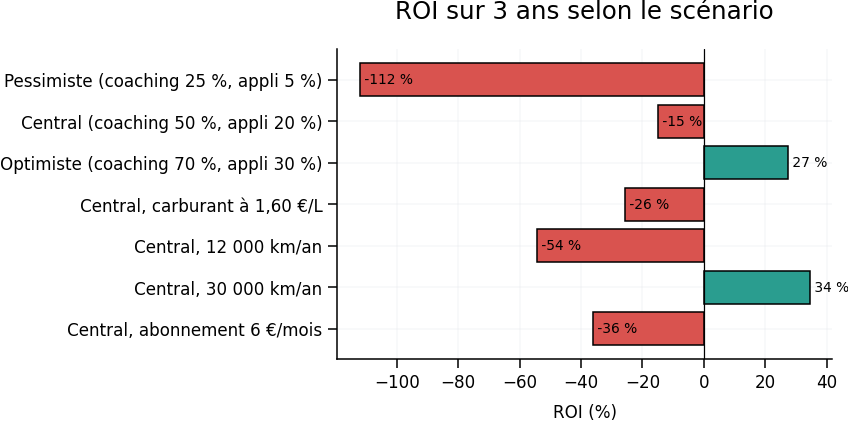

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
v = scen["ROI 3 ans (%)"][::-1].astype(float)
ax.barh(v.index, v, color=["#d9534f" if x < 0 else "#2a9d8f" for x in v]); ax.axvline(0, color="k", lw=.8)
for i, x in enumerate(v): ax.text(x, i, f" {x:.0f} %", va="center", fontsize=9)
ax.set(title="ROI sur 3 ans selon le scénario", xlabel="ROI (%)")
plt.tight_layout(); plt.savefig(FIG / "03_roi.png", bbox_inches="tight"); plt.show()

**Lecture :** l'essentiel du gain vient du carburant (coaching ciblé). L'hypothèse la plus critique est la part du
potentiel réellement rattrapée par les conducteurs → à mesurer pendant un pilote de 3 mois.

In [9]:
sauver("decision", {"hyp": HYP, "seuil_train": seuil_choisi, "n_blocs_train": int(tr.bloc.nunique()),
    "styles": comp_style.round(4).reset_index().to_dict("records"),
    "n_blocs_test": int(test.bloc.nunique()), "n_simulations": 30,
    "tableau_modele": tab_m.round(4).to_dict("records"), "tableau_regle": tab_r.round(4).to_dict("records"),
    "seuil": float(best.seuil), "recall": float(best.recall), "precision": float(best.precision), "fp_an": float(best["FP/an"]),
    "cout_modele": float(best["coût annuel (€)"]), "cout_regle": float(best_r["coût annuel (€)"]), "cout_sans": float(cout_sans),
    "pot_coach": float(pot_coach), "pot_autres": float(pot_autres), "conso_ice": float(conso_ice),
    "roi": scen.reset_index().rename(columns={"index": "scenario"}).to_dict("records")})